# Fase A · Análisis Exploratorio — Siniestralidad vial en Cali 2016–2024

**Proyecto 2 y 3 · Grupo DatosSinCiencia**

**Objetivo:** caracterizar el dataset de siniestralidad vial de Santiago de Cali con estadísticos y gráficas adecuadas para
cada tipo de variable, y traducir lo que revelan los datos a hallazgos de negocio.

**Dataset:** `siniestralidad_2016_2024.csv` — un registro por cada siniestro de tránsito reportado a la Secretaría de
Movilidad de Cali, entre el 1-ene-2016 y el 2-nov-2024.

**Pregunta de negocio:** *¿qué características de un siniestro se asocian con su gravedad (solo daños, con lesionados o con
fallecidos), para focalizar la prevención y priorizar la atención?*

> **Regla de oro (Clase 4):** siempre clasifica primero tus variables antes de calcular nada.

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from dotenv import load_dotenv

load_dotenv()      # lee la ruta del CSV desde el archivo .env (ver .env.example)
RUTA_CSV = os.getenv("RUTA_CSV", "../siniestralidad_2016_2024.csv")

df = pd.read_csv(RUTA_CSV, sep=";", encoding="latin-1", dtype=str)
print(f"Dataset: {len(df):,} filas × {df.shape[1]} columnas")
df.head()

Dataset: 371,003 filas × 10 columnas


,Código,Fecha,Tipo confirmado,Dirección reporte,Tipo clase de accidente,Tipo clase de accidente.1,Tipo confirmado.1,Medio de reporte,Numero vehículos,Tipo de vehículos implicados
0,96159,1/01/2016,Solo daños,Carrera 56 Con Calle 1 A,.,.,Solo Da?os,RADIO,2,MOTOCICLETA
1,96160,1/01/2016,Negativo,Calle 72 O Con Carrera 28 H,.,.,Negativo,RADIO,.,.
2,96161,1/01/2016,Con lesionado,Carrera 94 Con Calle 4 C,ATROPELLO,ATROPELLO,Por Atropello,TELEF?NICO 127,2,MOTOCICLETA
3,96162,1/01/2016,Con lesionado,Carrera 8 A Con Calle 44,VOLCAMIENTO,VOLCAMIENTO,Por Volcamiento,RADIO,1,MOTOCICLETA
4,96163,1/01/2016,Negativo,Carrera 28 H Con Calle 72 M,.,.,Negativo,TELEF?NICO 127,.,.


## Sección 1 — Perfil del dataset

El archivo **no viene en UTF-8 sino en Latin-1** y usa `;` como separador, por eso se especifican `encoding` y `sep` al
cargarlo. Se lee todo como texto (`dtype=str`) para ver los valores tal como llegan, antes de convertir tipos.

In [2]:
print(df.dtypes)

Código                          str
Fecha                           str
Tipo confirmado                 str
Dirección reporte               str
Tipo clase de accidente         str
Tipo clase de accidente.1       str
Tipo confirmado.1               str
Medio de reporte                str
Numero vehículos                str
Tipo de vehículos implicados    str
dtype: object


In [3]:
# ¿Cómo vienen marcados los datos faltantes? En este archivo NO son celdas vacías sino un punto "."
diag = pd.DataFrame({
    "n_nulos":  df.isna().sum(),
    "n_punto":  (df == ".").sum(),
    "pct_sin_dato": ((df.isna() | (df == ".")).mean() * 100).round(1),
    "valores_unicos": df.nunique(),
})
print(diag.sort_values("pct_sin_dato", ascending=False))

print(f"\nFilas duplicadas: {df.duplicated().sum():,}")
print(f"¿Las dos columnas 'Tipo clase de accidente' son iguales? "
      f"{df['Tipo clase de accidente'].equals(df['Tipo clase de accidente.1'])}")

                              n_nulos  n_punto  pct_sin_dato  valores_unicos
Tipo clase de accidente             1   325257          87.7              15
Tipo clase de accidente.1           1   325257          87.7              15
Medio de reporte                    0   288099          77.7              18
Tipo de vehículos implicados        0   222214          59.9             844
Numero vehículos                    0   194424          52.4              13
Dirección reporte              181593     2093          49.5           65335
Tipo confirmado.1                   0    23389           6.3              22
Código                              1        0           0.0          370998
Fecha                               1        0           0.0            3229
Tipo confirmado                     1        2           0.0               7



Filas duplicadas: 4
¿Las dos columnas 'Tipo clase de accidente' son iguales? True


In [4]:
# Texto inconsistente: la misma categoría escrita de varias formas
print(df["Tipo confirmado"].value_counts())
print()
print(df["Tipo clase de accidente"].value_counts())

Tipo confirmado
Negativo                   246110
Solo daños                  73828
Con lesionado               47500
Con fallecido                2907
Con fallecido (Foraneo)       453
Solo Daños                    202
.                               2
Name: count, dtype: int64

Tipo clase de accidente
.                    325257
Choque                20548
CHOQUE                12084
ATROPELLO              5618
NO APLICA              2819
VOLCAMIENTO            1350
CAIDA DE OCUPANTE      1105
Atropello               993
Volcamiento             588
Ca?da Ocupante          371
OTRO                    118
Otro                     82
NOAPLICA                 66
Da?os                     2
Incendio                  1
Name: count, dtype: int64


**Lo que muestra el perfil:**

- Todas las columnas llegan como texto: `Fecha` debe pasar a fecha y `Numero vehículos` a número.
- Los faltantes vienen como `"."`; si no se convierten a `NaN`, pandas los cuenta como datos válidos.
- El encabezado repite columnas: `Tipo clase de accidente` aparece dos veces (idénticas) y `Tipo confirmado` también;
  la segunda (`Tipo confirmado.1`) es un *detalle* del resultado ("Arreglo Formal", "Falsa Alarma", "Inspección a cadáver"…).
- Hay texto inconsistente (`Solo daños` / `Solo Daños`, `CHOQUE` / `Choque`) y tildes dañadas por la codificación (`Ca?da`).
- Hay 4 filas duplicadas y la última fila del archivo está vacía.

### Clasificación de las variables

In [5]:
clasificacion = pd.DataFrame({
    "columna": ["Código", "Fecha", "Tipo confirmado", "Dirección reporte", "Tipo clase de accidente",
                "Tipo confirmado.1", "Medio de reporte", "Numero vehículos", "Tipo de vehículos implicados"],
    "tipo": ["Identificador", "Fecha (temporal)", "Categórica ordinal", "Categórica nominal (texto libre)",
             "Categórica nominal", "Categórica nominal", "Categórica nominal", "Numérica discreta",
             "Categórica nominal (lista)"],
    "comentario": ["Un código por reporte", "Día del reporte", "Gravedad: Negativo < Solo daños < Con lesionado < Con fallecido",
                   "Cruce de calles o lugar", "Choque, atropello, volcamiento…", "Detalle del resultado",
                   "Línea 123, 127, radio…", "Cantidad de vehículos", "Ej.: 'AUTOMOVIL,MOTOCICLETA'"],
})
clasificacion

,columna,tipo,comentario
0,Código,Identificador,Un código por reporte
1,Fecha,Fecha (temporal),Día del reporte
2,Tipo confirmado,Categórica ordinal,Gravedad: Negativo < Solo daños < Con lesionad...
3,Dirección reporte,Categórica nominal (texto libre),Cruce de calles o lugar
4,Tipo clase de accidente,Categórica nominal,"Choque, atropello, volcamiento…"
5,Tipo confirmado.1,Categórica nominal,Detalle del resultado
6,Medio de reporte,Categórica nominal,"Línea 123, 127, radio…"
7,Numero vehículos,Numérica discreta,Cantidad de vehículos
8,Tipo de vehículos implicados,Categórica nominal (lista),"Ej.: 'AUTOMOVIL,MOTOCICLETA'"


El dataset tiene **una sola variable numérica original** (`Numero vehículos`). Para poder hacer histogramas, boxplots y
correlación se crean variables numéricas a partir de la fecha y de la lista de vehículos (Sección 2).

La variable objetivo es **`Tipo confirmado`** (gravedad), que es **ordinal**: tiene un orden natural de menos a más grave.

## Sección 2 — Preparación mínima para el análisis

Aquí solo se hace lo indispensable para poder explorar. La limpieza completa (imputación, outliers, encoding, escalado)
corresponde a la **Fase B**.

| Paso | Por qué |
|---|---|
| `"."` → `NaN` | Para que los faltantes se puedan contar y graficar |
| Quitar fila vacía y duplicados | Son 5 filas que no representan siniestros distintos |
| Unificar `Tipo confirmado` → `GRAVEDAD` | "Solo Daños" = "Solo daños"; "Con fallecido (Foraneo)" = fallecido residente fuera de Cali |
| `GRAVEDAD_NUM` (0 a 3) | Versión numérica de la gravedad, para la correlación |
| Variables de fecha | Año, mes y día de la semana |
| Conteo de vehículos por tipo | Cuántas motos, autos, buses, vehículos de carga y bicicletas hay en cada siniestro |

In [6]:
df = df.replace(".", np.nan)
df = df.dropna(subset=["Fecha"])          # la última fila del archivo está vacía
df = df.drop_duplicates()

# Fecha
df["FECHA"] = pd.to_datetime(df["Fecha"], format="%d/%m/%Y")
df["ANIO"] = df["FECHA"].dt.year
df["MES"] = df["FECHA"].dt.month
df["DIA_SEMANA"] = df["FECHA"].dt.day_of_week        # 0 = lunes ... 6 = domingo

# Número de vehículos (hay 5 valores escritos como "1.")
df["NUM_VEHICULOS"] = pd.to_numeric(df["Numero vehículos"].str.replace(".", "", regex=False), errors="coerce")

# Gravedad
ORDEN_GRAVEDAD = ["Negativo", "Solo daños", "Con lesionado", "Con fallecido"]
df["GRAVEDAD"] = df["Tipo confirmado"].replace({"Solo Daños": "Solo daños",
                                                "Con fallecido (Foraneo)": "Con fallecido"})
df = df[df["GRAVEDAD"].isin(ORDEN_GRAVEDAD)]
df["GRAVEDAD_NUM"] = df["GRAVEDAD"].map({"Negativo": 0, "Solo daños": 1, "Con lesionado": 2, "Con fallecido": 3})

# Conteo de vehículos por tipo dentro de la lista (NaN cuando no hay dato de vehículos)
veh = df["Tipo de vehículos implicados"].str.upper()
df["N_MOTOS"]   = veh.str.count("MOTOCICLETA|MOTOCICLO|MOTOCARRO")
df["N_AUTOS"]   = veh.str.count("AUTOMOVIL|CAMIONETA|CAMPERO")
df["N_PUBLICO"] = veh.str.count(r"\bBUS|MICROBUS|MINIBUS")
df["N_CARGA"]   = veh.str.count(r"CAMION(?!ETA)|VOLQUETA|GRUA")      # CAMION pero no CAMIONETA
df["N_BICIS"]   = veh.str.count("BICICLETA")

print(f"Dataset para el análisis: {len(df):,} filas")
print(df["GRAVEDAD"].value_counts())

Dataset para el análisis: 370,996 filas
GRAVEDAD
Negativo         246107
Solo daños        74029
Con lesionado     47500
Con fallecido      3360
Name: count, dtype: int64


## Sección 3 — Estadísticos descriptivos

| Situación | Medida recomendada |
|---|---|
| Variable simétrica, sin outliers | Media |
| Variable asimétrica o con outliers | Mediana |
| Variable categórica | Moda |

Además se calcula el **coeficiente de variación** (CV = desv. estándar / media × 100) y la **asimetría**:
si |asimetría| > 1 la distribución es marcadamente asimétrica y la mediana describe mejor los datos.

In [7]:
NUMERICAS = ["NUM_VEHICULOS", "N_MOTOS", "N_AUTOS", "N_PUBLICO", "N_CARGA", "N_BICIS", "GRAVEDAD_NUM"]

estadisticos = df[NUMERICAS].agg(["mean", "median", "std", "min", "max",
                                  lambda x: x.quantile(0.75) - x.quantile(0.25)])
estadisticos.index = ["Media", "Mediana", "Desv. Estándar", "Mínimo", "Máximo", "IQR (Q3-Q1)"]
print(estadisticos.round(2))

print("\nCoeficiente de Variación (%):")
print((df[NUMERICAS].std() / df[NUMERICAS].mean() * 100).round(1))

print("\n=== Asimetría y Curtosis ===")
print(df[NUMERICAS].agg(["skew", "kurt"]).round(2))

print("\nModa de las variables categóricas:")
for col in ["GRAVEDAD", "Tipo clase de accidente", "Medio de reporte"]:
    print(f"  {col}: {df[col].mode()[0]}")

                NUM_VEHICULOS  N_MOTOS  N_AUTOS  N_PUBLICO  N_CARGA  N_BICIS  \
Media                    1.95     0.52     1.16       0.09     0.07     0.01   
Mediana                  2.00     0.00     1.00       0.00     0.00     0.00   
Desv. Estándar           0.44     0.62     0.79       0.31     0.27     0.09   
Mínimo                   1.00     0.00     0.00       0.00     0.00     0.00   
Máximo                  16.00     5.00     5.00       5.00     3.00     2.00   
IQR (Q3-Q1)              0.00     1.00     1.00       0.00     0.00     0.00   

                GRAVEDAD_NUM  
Media                   0.48  
Mediana                 0.00  
Desv. Estándar          0.75  
Mínimo                  0.00  
Máximo                  3.00  
IQR (Q3-Q1)             1.00  

Coeficiente de Variación (%):
NUM_VEHICULOS      22.5
N_MOTOS           118.1
N_AUTOS            67.9
N_PUBLICO         325.4
N_CARGA           369.7
N_BICIS          1067.8
GRAVEDAD_NUM      155.0
dtype: float64

=== Asi

  GRAVEDAD: Negativo
  Tipo clase de accidente: Choque
  Medio de reporte: TELEF?NICO 127


**Lectura de la tabla:** el siniestro típico en Cali es **un choque entre dos vehículos** (media ≈ mediana ≈ 2), en cuatro
de cada cinco casos con un automóvil y en casi la mitad con una moto. Buses, camiones y bicicletas aparecen pocas veces
(mediana 0), pero eso no los hace menos importantes: como se verá en la Sección 8, cuando hay una bicicleta o una moto el
siniestro es mucho más grave. Por eso la Secretaría no debería decidir sus prioridades solo por el volumen de casos de cada
tipo de vehículo. El resultado más frecuente de un reporte es **"Negativo"**: lo más común es que el agente acuda y no
encuentre un siniestro que atender.

## Sección 4 — Calidad de los datos: ¿qué tan completo está cada campo?

Un mapa de faltantes es más informativo que solo el conteo: muestra si los nulos son aleatorios o si responden a un
**problema sistemático de captura** (Clase 5).

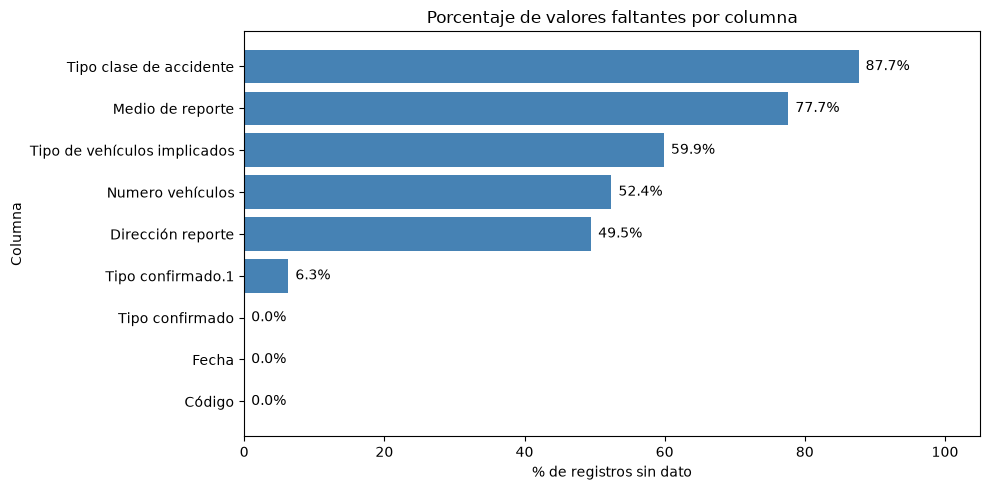

In [8]:
COLUMNAS_ORIGINALES = ["Código", "Fecha", "Tipo confirmado", "Dirección reporte", "Tipo clase de accidente",
                       "Tipo confirmado.1", "Medio de reporte", "Numero vehículos", "Tipo de vehículos implicados"]
pct_nulos = (df[COLUMNAS_ORIGINALES].isna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(pct_nulos.index, pct_nulos.values, color="steelblue")
for i, v in enumerate(pct_nulos.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_title("Porcentaje de valores faltantes por columna")
ax.set_xlabel("% de registros sin dato")
ax.set_ylabel("Columna")
ax.set_xlim(0, 105)
plt.tight_layout()
plt.show()

**Insight:** Solo la fecha y el resultado del reporte (`Tipo confirmado`) están completos; los campos que describen *cómo*
ocurrió el siniestro son los menos diligenciados: la clase de accidente falta en el 87,7% de los registros y el medio de
reporte en el 77,7%. Para la Secretaría de Movilidad esto significa que con este sistema no puede responder, para todo el
periodo, preguntas básicas como "¿cuántos atropellos hubo?".

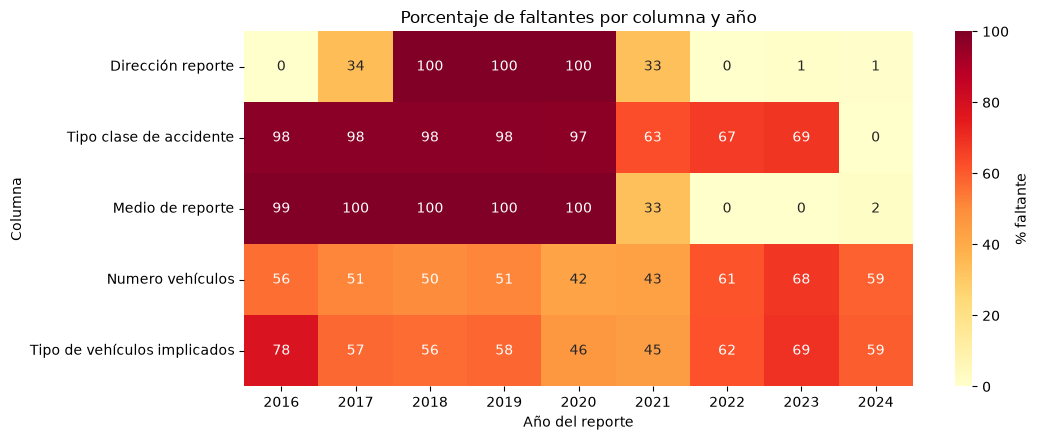

In [9]:
cols_faltantes = ["Dirección reporte", "Tipo clase de accidente", "Medio de reporte",
                  "Numero vehículos", "Tipo de vehículos implicados"]
nulos_anio = df[cols_faltantes].isna().groupby(df["ANIO"]).mean().T * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(nulos_anio, annot=True, fmt=".0f", cmap="YlOrRd", vmin=0, vmax=100,
            cbar_kws={"label": "% faltante"}, ax=ax)
ax.set_title("Porcentaje de faltantes por columna y año")
ax.set_xlabel("Año del reporte")
ax.set_ylabel("Columna")
plt.tight_layout()
plt.show()

**Insight:** Los faltantes **dependen del año**, porque el formulario de captura cambió varias veces: la dirección no se
registró entre 2018 y 2020, el medio de reporte solo existe desde 2021 y la clase de accidente solo está casi completa en
2024. En la práctica, la Secretaría **no puede saber con estos datos si los atropellos o los siniestros en un punto de la
ciudad subieron o bajaron entre años**, ni medir si una intervención funcionó, porque el dato no existía antes. Mantener el
mismo formulario año tras año es requisito para evaluar cualquier política de seguridad vial.

## Sección 5 — Histogramas de las variables numéricas

**¿Qué muestra?** La forma de la distribución (simétrica, sesgada, bimodal) antes de modelar. En las variables de conteo
se usa **eje Y logarítmico** para que los valores poco frecuentes (colas) se alcancen a ver.

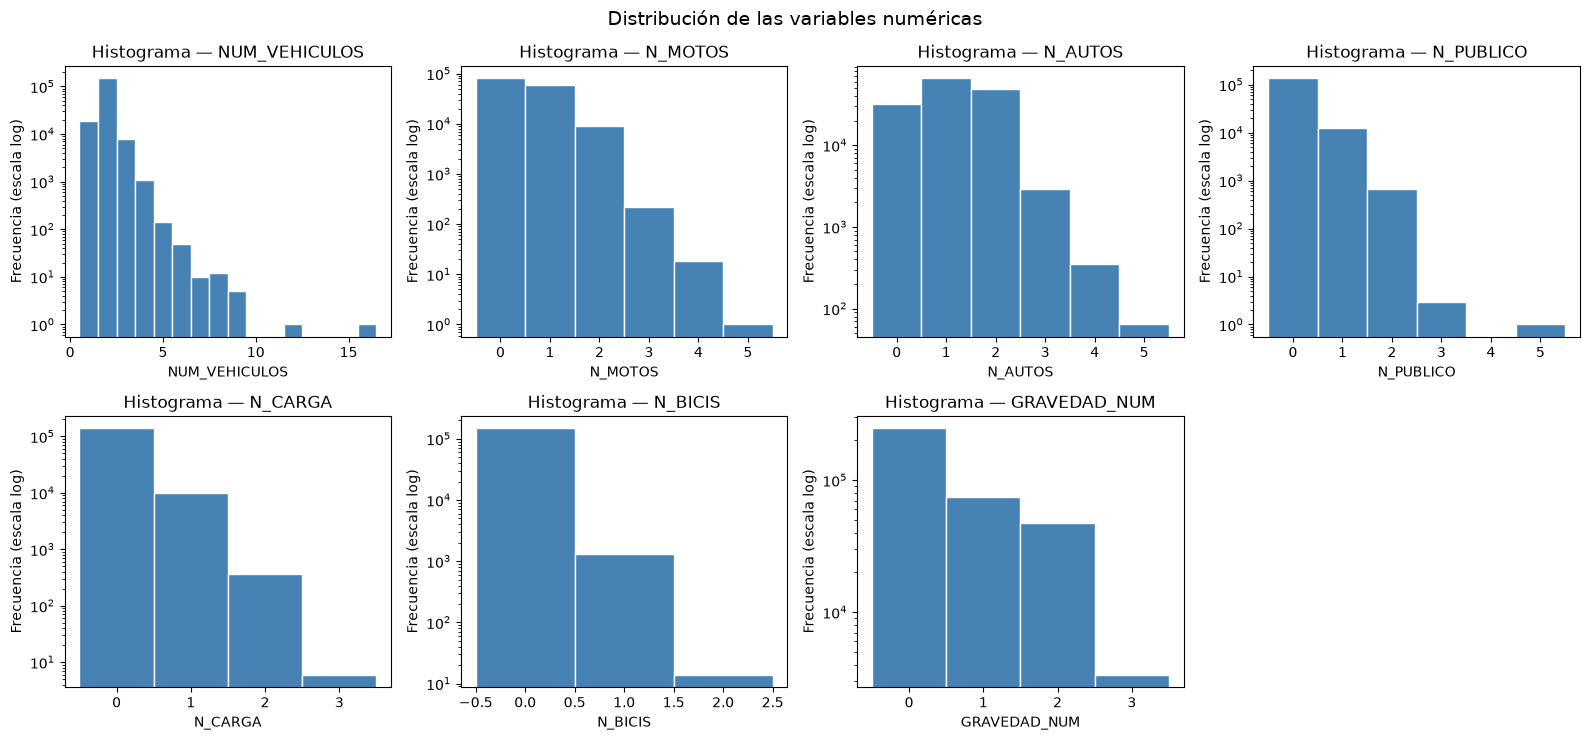

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))

for ax, col in zip(axes.flat, NUMERICAS):
    datos = df[col].dropna()
    ax.hist(datos, bins=np.arange(datos.min() - 0.5, datos.max() + 1.5), color="steelblue", edgecolor="white")
    ax.set_yscale("log")
    ax.set_title(f"Histograma — {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia (escala log)")

axes.flat[-1].axis("off")
plt.suptitle("Distribución de las variables numéricas", fontsize=14)
plt.tight_layout()
plt.show()

**Insight:** Casi todos los siniestros involucran 1 o 2 vehículos; los choques múltiples (5 o más) son excepcionales.
En gravedad, la mayoría de reportes termina sin víctimas, y los **fallecidos son apenas el 0,9% de los casos, aunque son
3.360 muertes en ocho años (≈1 por día)**: el problema más costoso para la ciudad es también el menos frecuente. Un
indicador basado en promedios o en el total de reportes esconde ese problema, por eso la Secretaría debería seguir los
fallecidos y lesionados como indicador propio. En la Fase C este desbalance obliga a evaluar los modelos por su capacidad
de detectar los casos graves, no por su acierto global.

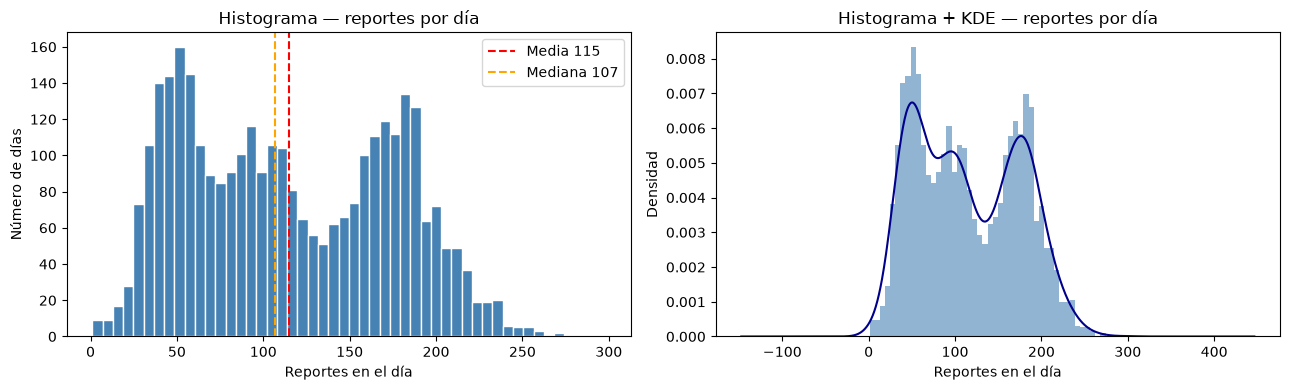

In [11]:
REPORTES_DIA = df.groupby("FECHA").size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(REPORTES_DIA, bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(REPORTES_DIA.mean(),   color="red",    linestyle="--", label=f"Media {REPORTES_DIA.mean():.0f}")
axes[0].axvline(REPORTES_DIA.median(), color="orange", linestyle="--", label=f"Mediana {REPORTES_DIA.median():.0f}")
axes[0].set_title("Histograma — reportes por día")
axes[0].set_xlabel("Reportes en el día")
axes[0].set_ylabel("Número de días")
axes[0].legend()

REPORTES_DIA.plot.hist(bins=50, density=True, alpha=0.6, ax=axes[1], color="steelblue")
REPORTES_DIA.plot.kde(ax=axes[1], color="darkblue")
axes[1].set_title("Histograma + KDE — reportes por día")
axes[1].set_xlabel("Reportes en el día")
axes[1].set_ylabel("Densidad")

plt.tight_layout()
plt.show()

**Insight:** Los reportes por día no forman una sola campana sino **varias "montañas"** (alrededor de 50, 100 y 180
reportes diarios). Eso indica que la ciudad pasó por periodos con volúmenes muy distintos (2016–2019, 2020–2022 y
2023–2024), algo que se confirma en la serie de tiempo de la Sección 8. Por eso la media (115) no describe bien un "día
típico" de ningún periodo.

## Sección 6 — Boxplots y detección de outliers con IQR

**Método IQR (regla de los bigotes de Tukey):**

1. Calcular Q1 (percentil 25) y Q3 (percentil 75).
2. Calcular IQR = Q3 − Q1.
3. Límite inferior = Q1 − 1.5 × IQR · Límite superior = Q3 + 1.5 × IQR.
4. Cualquier valor fuera de esos límites se considera outlier.

Un outlier puede ser un **error de captura** (hay que corregirlo) o un **valor legítimo extremo** (hay que reportarlo, no
eliminarlo).

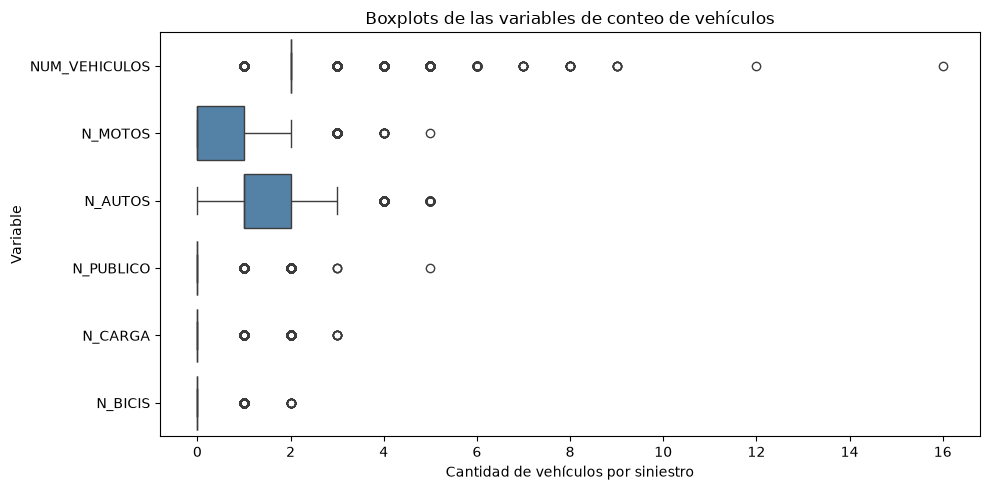

,variable,Q1,Q3,IQR,lim_inf,lim_sup,outliers,% outliers
0,NUM_VEHICULOS,2.0,2.0,0.0,2.0,2.0,28222,15.98
1,N_MOTOS,0.0,1.0,1.0,-1.5,2.5,238,0.16
2,N_AUTOS,1.0,2.0,1.0,-0.5,3.5,420,0.28
3,N_PUBLICO,0.0,0.0,0.0,0.0,0.0,13411,9.01
4,N_CARGA,0.0,0.0,0.0,0.0,0.0,10483,7.05
5,N_BICIS,0.0,0.0,0.0,0.0,0.0,1307,0.88
6,GRAVEDAD_NUM,0.0,1.0,1.0,-1.5,2.5,3360,0.91


In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df[NUMERICAS[:-1]], orient="h", color="steelblue", ax=ax)
ax.set_title("Boxplots de las variables de conteo de vehículos")
ax.set_xlabel("Cantidad de vehículos por siniestro")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.show()

filas = []
for col in NUMERICAS:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    filas.append({"variable": col, "Q1": Q1, "Q3": Q3, "IQR": IQR, "lim_inf": lim_inf, "lim_sup": lim_sup,
                  "outliers": len(outliers), "% outliers": round(len(outliers) / df[col].notna().sum() * 100, 2)})
pd.DataFrame(filas)

**Insight:** Como casi todos los siniestros tienen exactamente 2 vehículos (IQR = 0), la regla IQR marca como "atípicos"
a **28.222 siniestros (16%)**: unos 19.000 con un solo vehículo (atropellos, volcamientos, caídas de ocupante) y unos 9.200
choques en cadena de 3 o más vehículos. No son errores de captura: son justamente **los tipos de siniestro más graves para
la ciudad**, y borrarlos dejaría a la Secretaría sin información sobre peatones atropellados y choques múltiples. Por eso se
conservan, y solo los pocos casos con 9 o más vehículos se revisarán en la Fase B.

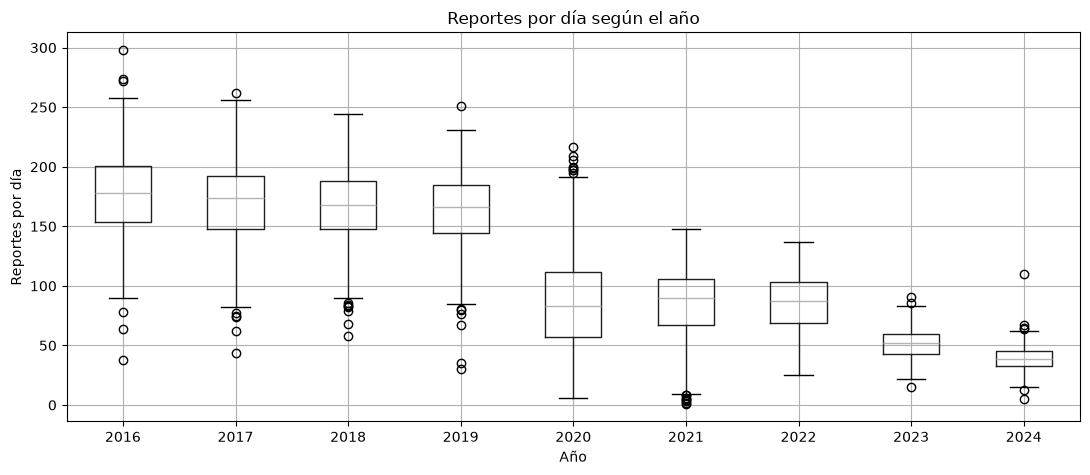

Días con menos reportes:
FECHA
2021-05-01    1
2021-05-04    2
2021-04-30    3
2021-05-03    4
2021-05-02    5
2024-01-22    5
dtype: int64


In [13]:
fig, ax = plt.subplots(figsize=(11, 5))
REPORTES_DIA.to_frame("REPORTES").assign(ANIO=REPORTES_DIA.index.year).boxplot(column="REPORTES", by="ANIO", ax=ax)
ax.set_title("Reportes por día según el año")
ax.set_xlabel("Año")
ax.set_ylabel("Reportes por día")
plt.suptitle("")      # quitar el supertítulo por defecto de boxplot
plt.tight_layout()
plt.show()

print("Días con menos reportes:")
print(REPORTES_DIA.nsmallest(6))

**Insight:** El volumen diario cae a la mitad en 2020 (de una mediana de ≈170 a ≈85 reportes/día) y no recupera el nivel
pre-pandemia; desde 2023 sigue bajando. Los días atípicamente bajos (1 a 5 reportes entre el 30-abr y el 4-may-2021)
coinciden con el **Paro Nacional**, cuando Cali tuvo bloqueos y el sistema de reportes operó parcialmente: son outliers
reales del registro, no errores, y deben conservarse.

## Sección 7 — Correlación entre variables numéricas

| | Pearson | Spearman |
|---|---|---|
| Mide | Relación lineal | Relación monótona (por rangos) |
| Cuándo usar | Variables con distribución normal, sin outliers | Distribuciones asimétricas, discretas u ordinales |
| Sensible a outliers | Sí | No |

Como las variables de este dataset son conteos sesgados y una ordinal (gravedad), **Spearman es la más apropiada**.

> ⚠️ **Correlación ≠ causalidad.**

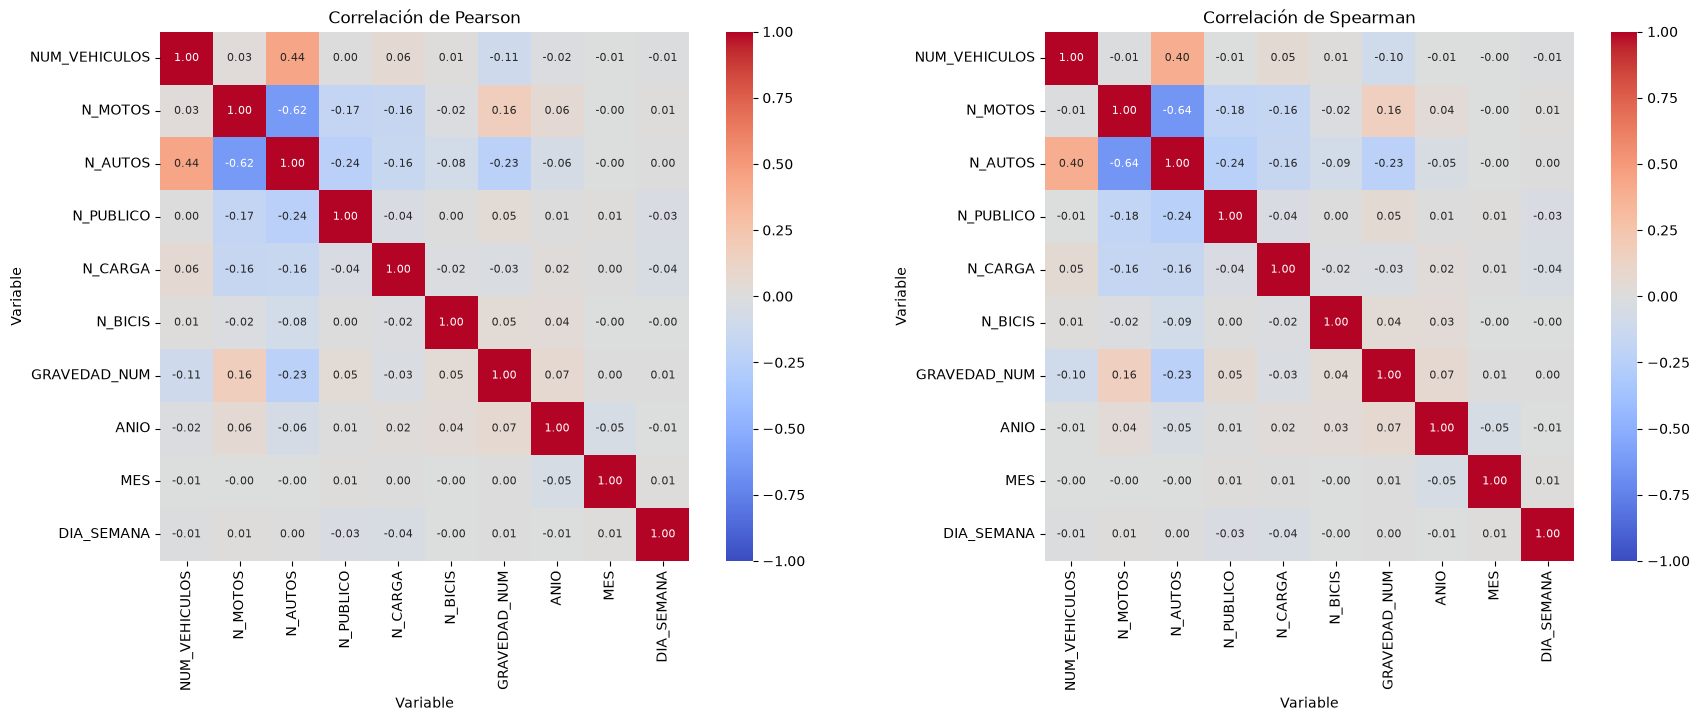

Correlación de Spearman con GRAVEDAD_NUM:


N_AUTOS         -0.229
NUM_VEHICULOS   -0.101
N_CARGA         -0.029
DIA_SEMANA       0.002
MES              0.006
N_BICIS          0.044
N_PUBLICO        0.050
ANIO             0.069
N_MOTOS          0.160
Name: GRAVEDAD_NUM, dtype: float64


In [14]:
VARS_CORR = NUMERICAS + ["ANIO", "MES", "DIA_SEMANA"]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, method, title in zip(axes, ["pearson", "spearman"],
                              ["Correlación de Pearson", "Correlación de Spearman"]):
    corr = df[VARS_CORR].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, square=True,
                annot_kws={"size": 8})
    ax.set_title(title)
    ax.set_xlabel("Variable")
    ax.set_ylabel("Variable")

plt.tight_layout()
plt.show()

print("Correlación de Spearman con GRAVEDAD_NUM:")
print(df[VARS_CORR].corr(method="spearman")["GRAVEDAD_NUM"].drop("GRAVEDAD_NUM").sort_values().round(3))

**Insight:** Las correlaciones con la gravedad son débiles pero coherentes en ambos métodos: **más motos se asocia a mayor
gravedad** (ρ ≈ +0,16) y **más autos a menor gravedad** (ρ ≈ −0,23), porque el ocupante de un carro va protegido y el
motociclista no. Las variables de calendario (mes, día de la semana) tienen correlación ≈ 0 con todo, y la relación
motos–autos (≈ −0,6) indica que esas dos variables comparten información.

## Sección 8 — Gráficos adicionales (repertorio Clase 4/5)

| Pregunta | Gráfico |
|---|---|
| ¿Qué tan graves son los reportes? | Barras |
| ¿Cómo evolucionó en el tiempo? | Líneas |
| ¿Qué actor vial es más vulnerable? | Barras apiladas |
| ¿Qué vehículos explican la mayoría de casos? | Pareto |
| ¿Qué día es más peligroso? | Violin + barras |
| ¿Qué tipo de accidente es más grave? | Barras apiladas |
| ¿Dónde se concentran? | Barras horizontales |

### 8.1 Barras — distribución de la gravedad

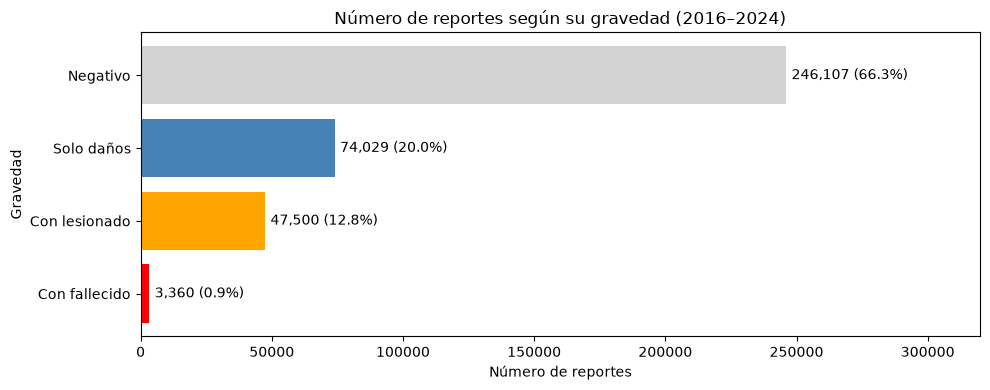

Detalle de los reportes 'Negativo':
Tipo confirmado.1
Negativo                  212384
No Quiere Intervenci?n     20663
NEGATIVO                    7300
Falsa Alarma                3773
POSITIVO                    1197
Name: count, dtype: int64


In [15]:
COLORES = {"Negativo": "lightgray", "Solo daños": "steelblue", "Con lesionado": "orange", "Con fallecido": "red"}
conteo = df["GRAVEDAD"].value_counts().reindex(ORDEN_GRAVEDAD)
pct = conteo / conteo.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(conteo.index, conteo.values, color=[COLORES[g] for g in conteo.index])
for i, (v, p) in enumerate(zip(conteo.values, pct.values)):
    ax.text(v + 2000, i, f"{v:,} ({p:.1f}%)", va="center")
ax.set_title("Número de reportes según su gravedad (2016–2024)")
ax.set_xlabel("Número de reportes")
ax.set_ylabel("Gravedad")
ax.set_xlim(0, conteo.max() * 1.3)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("Detalle de los reportes 'Negativo':")
print(df.loc[df["GRAVEDAD"] == "Negativo", "Tipo confirmado.1"].value_counts().head(5))

**Insight:** **Dos de cada tres reportes (66,3%) resultan "Negativo"**: el agente acude pero no se confirma un siniestro que
requiera intervención (falsa alarma, los implicados no quieren intervención o ya se retiraron). Es un costo operativo
enorme para la Secretaría de Movilidad. En el otro extremo, 3.360 reportes (0,9%) tuvieron fallecidos: la clase que más
importa y la más escasa.

### 8.2 Líneas — evolución en el tiempo

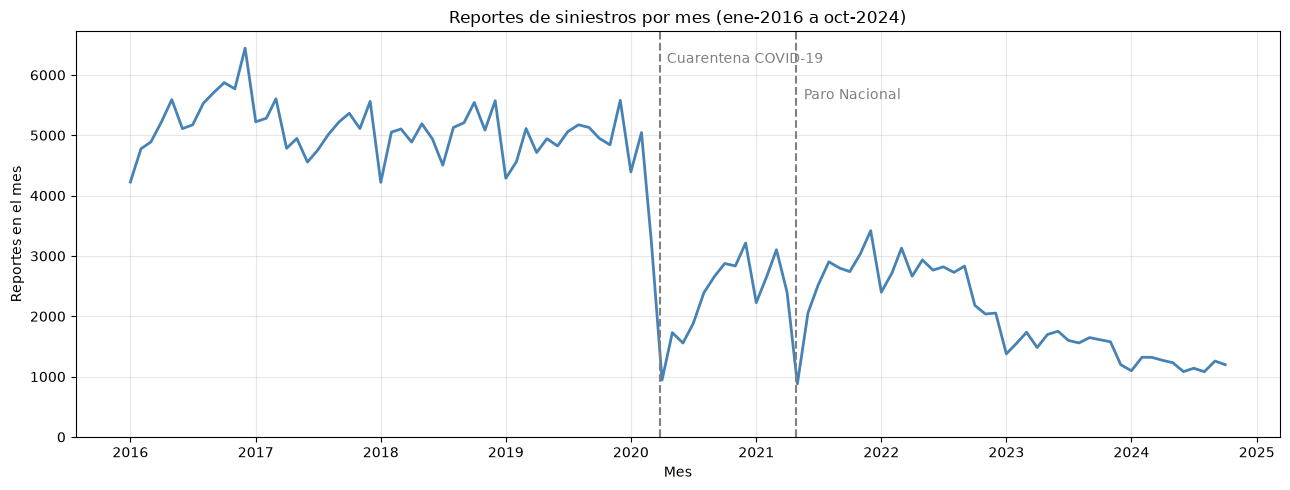

In [16]:
mensual = df.groupby(df["FECHA"].dt.to_period("M")).size()
mensual = mensual.iloc[:-1]          # noviembre de 2024 solo tiene 2 días de datos
mensual.index = mensual.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(mensual.index, mensual.values, color="steelblue", linewidth=2)
ax.axvline(pd.Timestamp("2020-03-25"), color="gray", linestyle="--")
ax.text(pd.Timestamp("2020-04-15"), 6200, "Cuarentena COVID-19", color="gray")
ax.axvline(pd.Timestamp("2021-04-28"), color="gray", linestyle="--")
ax.text(pd.Timestamp("2021-05-20"), 5600, "Paro Nacional", color="gray")
ax.set_title("Reportes de siniestros por mes (ene-2016 a oct-2024)")
ax.set_xlabel("Mes")
ax.set_ylabel("Reportes en el mes")
ax.set_ylim(0)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** La serie muestra un **quiebre en marzo de 2020**: el volumen pasa de ≈5.000 a ≈2.500–3.000 reportes al mes y
nunca regresa al nivel anterior, aunque la movilidad de la ciudad sí se recuperó; desde finales de 2022 vuelve a bajar
hasta ≈1.200 al mes en 2024. Esto sugiere que la caída responde más a cambios en cómo se reporta y se atiende que a menos
siniestros, y que un modelo entrenado solo con 2016–2019 no representaría la realidad actual.

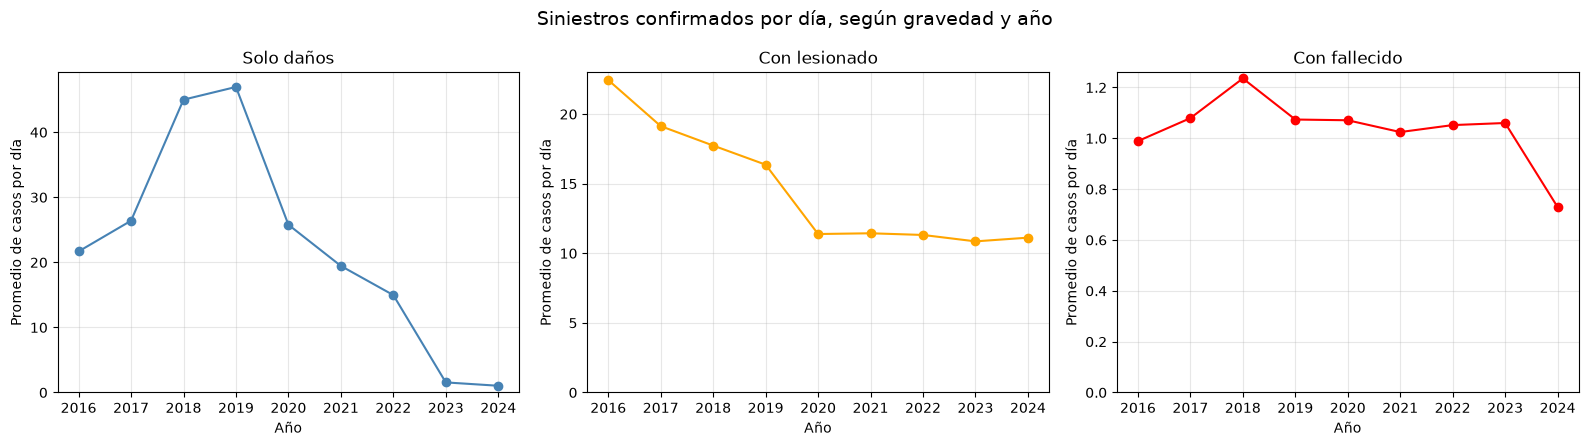

Casos por año (2024 llega hasta el 2-nov):
GRAVEDAD  Solo daños  Con lesionado  Con fallecido
ANIO                                              
2016            7936           8215            362
2017            9637           6985            394
2018           16428           6475            451
2019           17142           5974            392
2020            9437           4167            392
2021            7101           4175            374
2022            5464           4131            384
2023             566           3963            387
2024             318           3415            224


In [17]:
dias_por_anio = df.groupby("ANIO")["FECHA"].nunique()
por_anio = pd.crosstab(df["ANIO"], df["GRAVEDAD"])[ORDEN_GRAVEDAD[1:]]
promedio_diario = por_anio.div(dias_por_anio, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, g in zip(axes, ORDEN_GRAVEDAD[1:]):
    ax.plot(promedio_diario.index, promedio_diario[g], marker="o", color=COLORES[g])
    ax.set_title(f"{g}")
    ax.set_xlabel("Año")
    ax.set_ylabel("Promedio de casos por día")
    ax.set_ylim(0)
    ax.grid(alpha=0.3)
plt.suptitle("Siniestros confirmados por día, según gravedad y año", fontsize=14)
plt.tight_layout()
plt.show()

print("Casos por año (2024 llega hasta el 2-nov):")
print(por_anio)

**Insight:** Entre 2016 y 2023 los siniestros **con fallecido se mantienen casi constantes (≈1 por día, entre 360 y 450 al
año)**, aunque el total de reportes cayó a menos de la mitad; en cambio, los de "solo daños" se desploman desde 2023 (de 47
a 1–2 por día). Algunos reportes citan la Ley 2251 de 2022 para que los implicados resuelvan entre ellos los choques sin
heridos, lo que explicaría por qué esos casos dejaron de llegar al sistema: **menos reportes no significa una ciudad más
segura**.

### 8.3 Barras apiladas — gravedad según el actor vial implicado

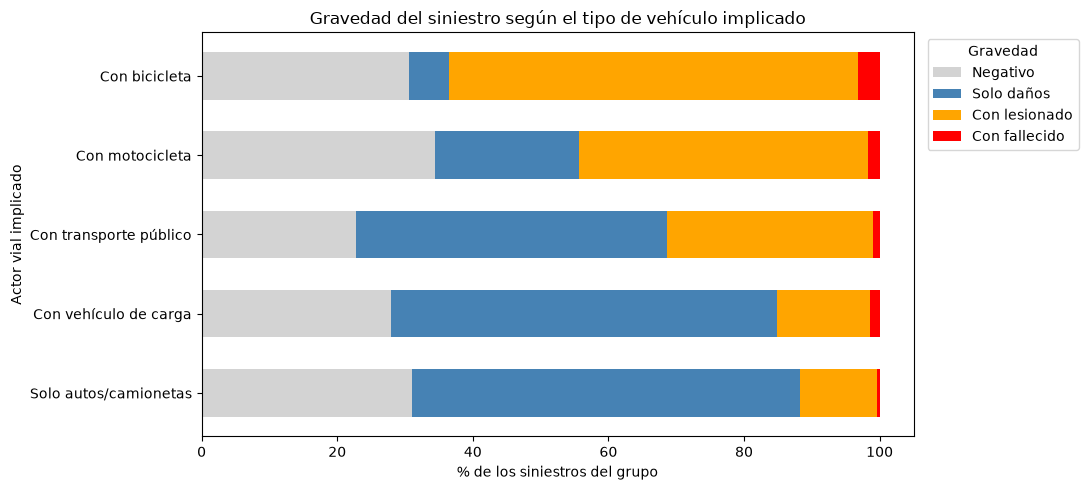

GRAVEDAD                Negativo  Solo daños  Con lesionado  Con fallecido  \
Solo autos/camionetas       31.0        57.2           11.5            0.3   
Con vehículo de carga       27.9        56.9           13.7            1.5   
Con transporte público      22.8        45.9           30.4            1.0   
Con motocicleta             34.4        21.3           42.7            1.7   
Con bicicleta               30.6         5.9           60.3            3.2   

GRAVEDAD                n_siniestros  
Solo autos/camionetas          60524  
Con vehículo de carga          10483  
Con transporte público         13411  
Con motocicleta                68217  
Con bicicleta                   1307  


In [18]:
con_vehiculos = df[df["Tipo de vehículos implicados"].notna()]
grupos = {
    "Con bicicleta":          con_vehiculos["N_BICIS"] > 0,
    "Con motocicleta":        con_vehiculos["N_MOTOS"] > 0,
    "Con transporte público": con_vehiculos["N_PUBLICO"] > 0,
    "Con vehículo de carga":  con_vehiculos["N_CARGA"] > 0,
    "Solo autos/camionetas":  (con_vehiculos["N_AUTOS"] > 0) &
                              (con_vehiculos[["N_MOTOS", "N_BICIS", "N_PUBLICO", "N_CARGA"]].sum(axis=1) == 0),
}
actor = pd.DataFrame({nombre: con_vehiculos.loc[filtro, "GRAVEDAD"].value_counts(normalize=True) * 100
                      for nombre, filtro in grupos.items()}).T[ORDEN_GRAVEDAD]
actor = actor.sort_values("Con lesionado")

fig, ax = plt.subplots(figsize=(11, 5))
actor.plot.barh(stacked=True, color=[COLORES[g] for g in ORDEN_GRAVEDAD], ax=ax, width=0.6)
ax.set_title("Gravedad del siniestro según el tipo de vehículo implicado")
ax.set_xlabel("% de los siniestros del grupo")
ax.set_ylabel("Actor vial implicado")
ax.legend(title="Gravedad", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

actor["n_siniestros"] = pd.Series({nombre: filtro.sum() for nombre, filtro in grupos.items()})
print(actor.round(1))

**Insight:** El riesgo depende de quién va expuesto: **con una bicicleta, el 60% de los siniestros deja lesionados y el
3,2% fallecidos; con una moto, 43% y 1,7%**, frente a 11,5% y 0,3% cuando solo chocan autos o camionetas (una moto hace el
siniestro 5 veces más letal). El transporte público también sobresale (30% con lesionados, por pasajeros que se golpean o
caen dentro del bus). Motociclistas y ciclistas son el grupo donde la prevención salvaría más vidas.

In [19]:
# ¿El dato de vehículos está igual de completo en todos los resultados?
print("% de reportes SIN dato de vehículos, según la gravedad:")
print((df["Tipo de vehículos implicados"].isna().groupby(df["GRAVEDAD"]).mean() * 100).round(1).reindex(ORDEN_GRAVEDAD))

% de reportes SIN dato de vehículos, según la gravedad:
GRAVEDAD
Negativo         80.9
Solo daños       18.7
Con lesionado    15.8
Con fallecido    55.3
Name: Tipo de vehículos implicados, dtype: float64


> ⚠️ **Nota para la Fase C (fuga de datos):** el dato de vehículos depende del resultado del caso: falta en el **81% de
> los reportes "Negativo"**, pero solo en el 16–19% de los siniestros con lesionados o solo daños (y en el 55% de los
> fallecidos). Por eso estas variables sirven para explicar la gravedad **entre siniestros confirmados**, pero no para
> predecir si un reporte resultará "Negativo": el modelo "adivinaría" a partir del hueco, no del siniestro.

### 8.4 Pareto — tipos de vehículo implicados

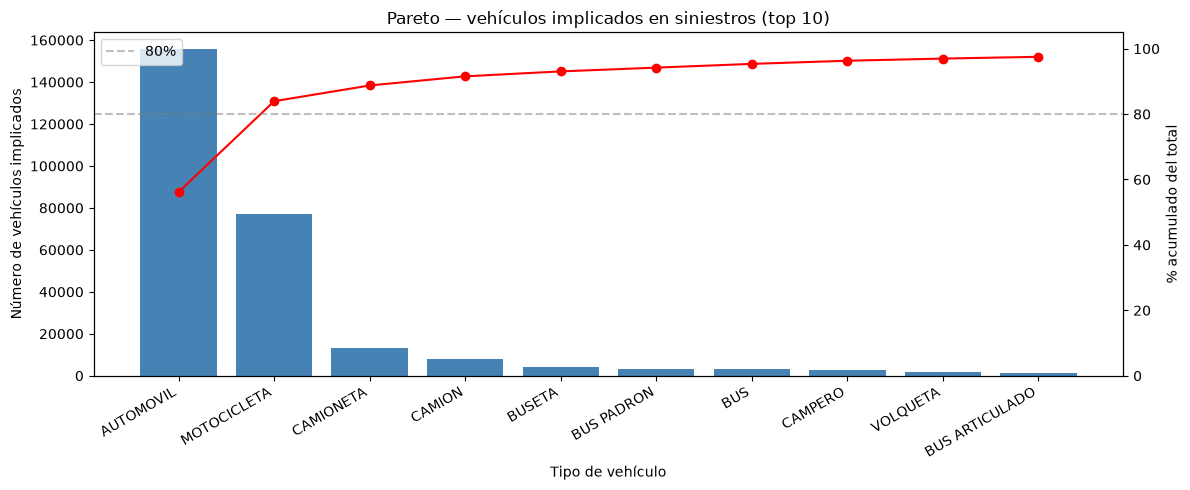

Tipo de vehículos implicados
AUTOMOVIL      56.2
MOTOCICLETA    83.9
CAMIONETA      88.8
CAMION         91.5
Name: count, dtype: float64


In [20]:
tipos = veh.str.replace('"', "", regex=False).str.split(",").explode().str.strip()
tipos = tipos[~tipos.isin(["0", "2", "SIN CLASE", "DESCONOCIDA"])].dropna()
conteo_tipos = tipos.value_counts().head(10)
acumulado = conteo_tipos.cumsum() / tipos.count() * 100

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(conteo_tipos.index, conteo_tipos.values, color="steelblue")
ax1.set_xlabel("Tipo de vehículo")
ax1.set_ylabel("Número de vehículos implicados")
ax1.set_xticks(range(len(conteo_tipos)))
ax1.set_xticklabels(conteo_tipos.index, rotation=30, ha="right")

ax2 = ax1.twinx()
ax2.plot(conteo_tipos.index, acumulado.values, color="red", marker="o")
ax2.axhline(80, color="gray", linestyle="--", alpha=0.5, label="80%")
ax2.set_ylabel("% acumulado del total")
ax2.set_ylim(0, 105)
ax2.legend()
ax1.set_title("Pareto — vehículos implicados en siniestros (top 10)")
plt.tight_layout()
plt.show()

print(acumulado.round(1).head(4))

**Insight:** **Automóviles y motocicletas suman el 84% de todos los vehículos implicados**: con solo dos tipos de vehículo
se explica la gran mayoría de la siniestralidad (principio 80/20). Para la Fase B esto justifica agrupar los ≈50 tipos de
vehículo en pocas categorías (moto, auto, transporte público, carga, bicicleta, otros) en lugar de crear decenas de
columnas One-Hot casi vacías.

### 8.5 Violin y barras — día de la semana

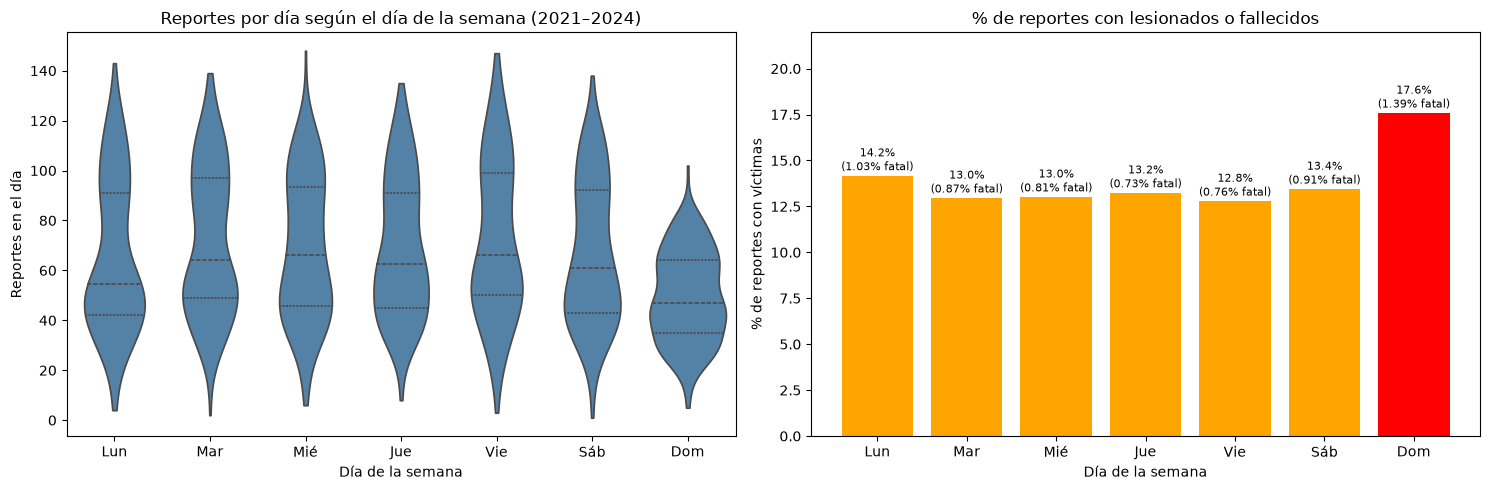

In [21]:
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia = REPORTES_DIA.to_frame("REPORTES")
por_dia["DIA"] = pd.Categorical([DIAS[d] for d in por_dia.index.day_of_week], categories=DIAS)
por_dia = por_dia[por_dia.index.year >= 2021]          # periodo de volumen actual

victimas = df.groupby("DIA_SEMANA")["GRAVEDAD"].apply(lambda s: s.isin(["Con lesionado", "Con fallecido"]).mean() * 100)
fatales = df.groupby("DIA_SEMANA")["GRAVEDAD"].apply(lambda s: (s == "Con fallecido").mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.violinplot(data=por_dia, x="DIA", y="REPORTES", color="steelblue", inner="quartile", cut=0, ax=axes[0])
axes[0].set_title("Reportes por día según el día de la semana (2021–2024)")
axes[0].set_xlabel("Día de la semana")
axes[0].set_ylabel("Reportes en el día")

axes[1].bar(DIAS, victimas.values, color=["orange"] * 6 + ["red"])
for i, (v, f) in enumerate(zip(victimas.values, fatales.values)):
    axes[1].text(i, v + 0.3, f"{v:.1f}%\n({f:.2f}% fatal)", ha="center", fontsize=8)
axes[1].set_title("% de reportes con lesionados o fallecidos")
axes[1].set_xlabel("Día de la semana")
axes[1].set_ylabel("% de reportes con víctimas")
axes[1].set_ylim(0, victimas.max() * 1.25)
plt.tight_layout()
plt.show()

**Insight:** **El domingo es el día con menos reportes pero los más graves**: el porcentaje con víctimas sube a 17,6% y el
de fallecidos a 1,4%, casi el doble que un jueves (0,7%). El lunes es el segundo día más letal (1,0%), coherente con que en
Colombia la mayoría de festivos caen en lunes. El patrón apunta a más velocidad en vías despejadas y consumo de alcohol en
días de descanso: los controles deberían concentrarse en domingos y festivos, no en los días de mayor volumen.

### 8.6 Barras apiladas — clase de accidente

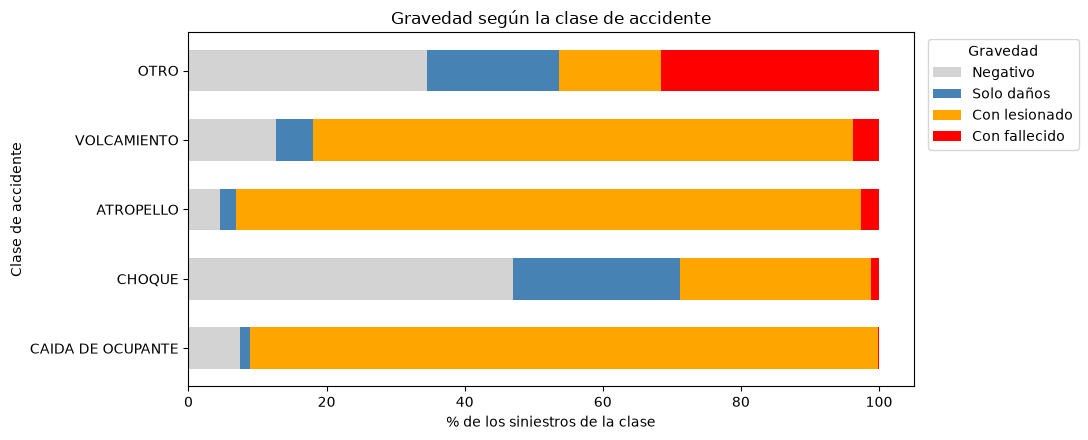

GRAVEDAD                 Negativo  Solo daños  Con lesionado  Con fallecido  \
Tipo clase de accidente                                                       
CAIDA DE OCUPANTE             7.5         1.4           91.0            0.1   
CHOQUE                       47.0        24.2           27.7            1.1   
ATROPELLO                     4.5         2.4           90.5            2.6   
VOLCAMIENTO                  12.7         5.4           78.2            3.8   
OTRO                         34.5        19.2           14.8           31.5   

GRAVEDAD                     n  
Tipo clase de accidente         
CAIDA DE OCUPANTE         1476  
CHOQUE                   32631  
ATROPELLO                 6610  
VOLCAMIENTO               1938  
OTRO                       203  


In [22]:
clase = df["Tipo clase de accidente"].str.upper().replace({"CA?DA OCUPANTE": "CAIDA DE OCUPANTE",
                                                           "NOAPLICA": "NO APLICA", "DA?OS": "OTRO",
                                                           "INCENDIO": "OTRO"})
con_clase = df[clase.notna() & (clase != "NO APLICA")]
tabla_clase = pd.crosstab(clase[con_clase.index], con_clase["GRAVEDAD"], normalize="index")[ORDEN_GRAVEDAD] * 100
tabla_clase = tabla_clase.sort_values("Con fallecido")

fig, ax = plt.subplots(figsize=(11, 4.5))
tabla_clase.plot.barh(stacked=True, color=[COLORES[g] for g in ORDEN_GRAVEDAD], ax=ax, width=0.6)
ax.set_title("Gravedad según la clase de accidente")
ax.set_xlabel("% de los siniestros de la clase")
ax.set_ylabel("Clase de accidente")
ax.legend(title="Gravedad", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

tabla_clase["n"] = clase[con_clase.index].value_counts()
print(tabla_clase.round(1))

**Insight:** Atropellos y caídas de ocupante casi siempre dejan víctimas (**≈91% con lesionados**), y el **volcamiento es la
clase más letal entre las frecuentes (3,8% con fallecidos)**, seguido del atropello (2,6%); el choque, aunque es la más
común, en su mayoría termina sin víctimas. La categoría "OTRO" (≈31% fatal) es pequeña y parece usarse para casos
registrados a partir del fallecimiento. Esta variable solo existe en el 12% de los registros, así que su uso en la Fase C
es limitado.

### 8.7 Barras horizontales — puntos críticos

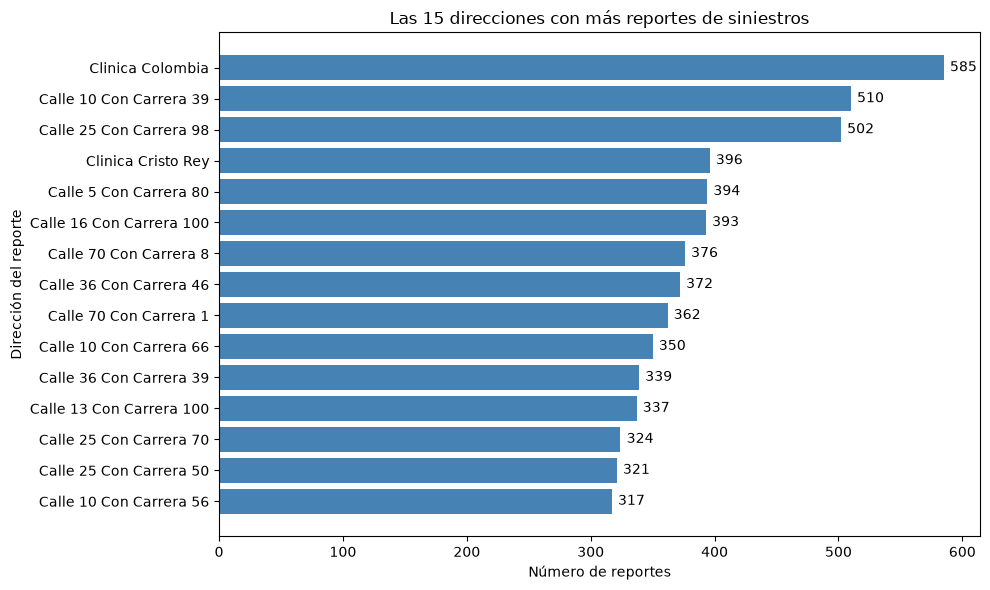

In [23]:
top_direcciones = df["Dirección reporte"].str.strip().str.title().value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_direcciones.index, top_direcciones.values, color="steelblue")
for i, v in enumerate(top_direcciones.values):
    ax.text(v + 5, i, f"{v}", va="center")
ax.set_title("Las 15 direcciones con más reportes de siniestros")
ax.set_xlabel("Número de reportes")
ax.set_ylabel("Dirección del reporte")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Insight:** Los puntos con más reportes se concentran en pocos corredores: **la Calle 10 y la Calle 25 aparecen tres veces
cada una en el top 15**, y la Calle 70 y la Calle 36 dos veces, lo que apunta a ejes completos más que a cruces aislados.
Dos de las "direcciones" más frecuentes son clínicas (Clínica Colombia, Clínica Cristo Rey): allí se registra el caso
cuando el lesionado llega al hospital, no donde ocurrió, algo que debe depurarse antes de cualquier análisis geográfico.

---

## ✅ Resumen — Hallazgos de la Fase A

| # | Hallazgo | Implicación para el negocio | Implicación para las Fases B y C |
|---|---|---|---|
| 1 | **Motos y bicicletas concentran la gravedad**: con bicicleta el 60% deja lesionados y el 3,2% fallecidos; con moto 43% y 1,7%; solo autos 11,5% y 0,3%. | Priorizar prevención y control para motociclistas y ciclistas. | El tipo de vehículo explica la gravedad entre siniestros **confirmados**; no sirve para predecir "Negativo" (fuga de datos: el dato falta en el 81% de los Negativo). |
| 2 | **66% de los reportes son "Negativo"** y solo el 0,9% tiene fallecidos. | Gran costo operativo en atenciones sin siniestro confirmado. | Clases muy desbalanceadas: split estratificado y métricas como Recall/F1, no solo Accuracy. |
| 3 | **El registro cambió con el tiempo**: quiebre en 2020, campos que solo existen en ciertos años y casi desaparición de "solo daños" desde 2023, mientras los fallecidos siguen en ≈1 por día. | Menos reportes no significa una ciudad más segura; el indicador confiable son los fallecidos. | Faltantes dependen del año → no imputar con un solo valor para todo el periodo; incluir el año y evaluar en datos recientes. |
| 4 | **Domingo** (y lunes festivo): menos reportes pero la mayor proporción de víctimas y fallecidos. | Controles de velocidad y alcoholemia en domingos y festivos. | El día de la semana entra como categórica (One-Hot), no como número. |
| 5 | La regla IQR marca como atípicos siniestros reales (IQR = 0); los días vacíos de 2021 son el Paro Nacional. | — | Tratar outliers con criterio, no eliminarlos por regla automática. |